In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

In [14]:
data_peak = np.load("data_1_2.npz")

centreline_peak = data_peak["centreline_peak"]
centreline_fit_peak = data_peak["centreline_fit_peak"]
z_coordinates = data_peak["z_coordinates_peak"]
inner_surf_fit_peak = data_peak["inner_surf_fit_peak"]
inner_surf_peak = data_peak["inner_surf_peak"]
residual_centreline_peak = data_peak["residual_centreline_peak"]
residual_surf_peak = data_peak["residual_surf_peak"]

data_average = np.load("data_1_1.npz")

centreline_average = data_average["centreline"]
centreline_fit_average = data_average["centreline_fit"]
inner_surf_average = data_average["inner_surf"]
inner_surf_fit_average = data_average["inner_surf_fit"]
residual_centreline_average = data_average["residual_centreline"]
residual_surf_average = data_average["residual_surf"]

resolved_x_range = np.linspace(0, 3.66, 100000)

In [11]:
color_list = ["#0072B2", "#009E73"]
marker_list = ["D", "s"]

labels = ["Average Centreline", "Peak Centreline", "Average Inner Clading", "Peak Inner Cladding"]

from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

legend_elements_1 = []

for color, marker, label in zip(color_list, marker_list, labels[0:2]):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='--',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements_1.append(((line, marker_handle), label))

legend_elements_2 = []

for color, marker, label in zip(color_list, marker_list, labels[2:]):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='--',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements_2.append(((line, marker_handle), label))

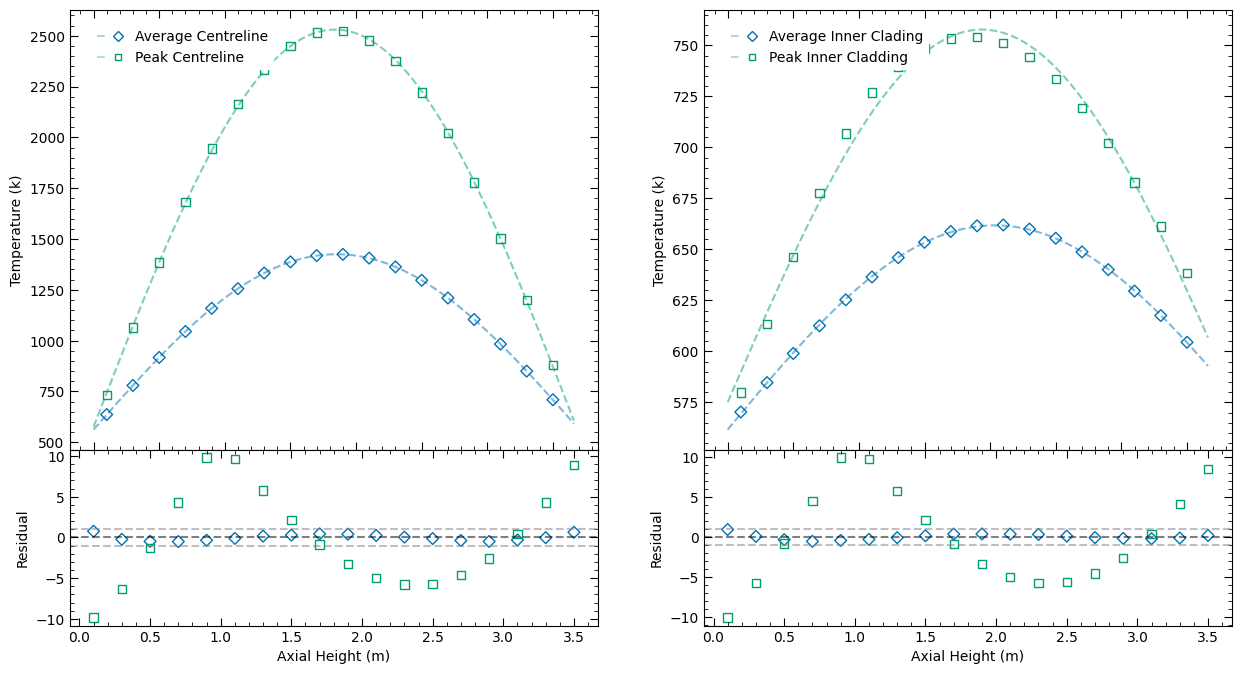

In [16]:
#######
# Setup
#######

fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[5, 2],
    hspace=0
)

ax_main_left = fig.add_subplot(gs[0, 0])
ax_res_left = fig.add_subplot(gs[1, 0])

ax_main_right = fig.add_subplot(gs[0, 1])
ax_res_right = fig.add_subplot(gs[1, 1])
################
# Main Plot Left
################

for ydata, yfit, colour, marker in zip(
        [centreline_average, centreline_peak], [centreline_fit_average, centreline_fit_peak], color_list,
        marker_list):
    ax_main_left.scatter(z_coordinates, ydata,
                         marker=marker, color=colour, facecolor="none")

    ax_main_left.plot(resolved_x_range, yfit,
                      color=colour, marker="none", linestyle="--", alpha=0.5)

ax_main_left.legend(
    handles=[item[0] for item in legend_elements_1],
    labels=[item[1] for item in legend_elements_1],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.03, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

#################
# Main Plot Right
#################

for ydata, yfit, colour, marker in zip(
        [inner_surf_average, inner_surf_peak], [inner_surf_fit_average, inner_surf_fit_peak], color_list,
        marker_list):
    ax_main_right.scatter(z_coordinates, ydata,
                          marker=marker, color=colour, facecolor="none")

    ax_main_right.plot(resolved_x_range, yfit,
                       color=colour, marker="none", linestyle="--", alpha=0.5)

ax_main_right.legend(
    handles=[item[0] for item in legend_elements_2],
    labels=[item[1] for item in legend_elements_2],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.03, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

####################
# Residual Plot Left
####################


for residual, colour, marker in zip(
        [residual_centreline_average, residual_centreline_peak], color_list, marker_list):
    ax_res_left.scatter(z_coordinates, residual,
                        marker=marker, color=colour, facecolor="none")

ax_res_left.axhline(0, linestyle="--", color="black", alpha=0.5)
ax_res_left.axhline(1, linestyle="--", color="grey", alpha=0.5)
ax_res_left.axhline(-1, linestyle="--", color="grey", alpha=0.5)

ax_res_left.set_ylabel("Residual")
ax_res_right.set_ylabel("Residual")

#####################
# Residual Plot Right
#####################


for residual, colour, marker in zip(
        [residual_surf_average, residual_surf_peak], color_list, marker_list):
    ax_res_right.scatter(z_coordinates, residual,
                         marker=marker, color=colour, facecolor="none")

ax_res_right.axhline(0, linestyle="--", color="black", alpha=0.5)
ax_res_right.axhline(1, linestyle="--", color="grey", alpha=0.5)
ax_res_right.axhline(-1, linestyle="--", color="grey", alpha=0.5)

#####################
# Formatting and Save
#####################

ax_res_left.set_xlabel("Axial Height (m)")
ax_main_left.set_ylabel("Temperature (k)")

ax_res_right.set_xlabel("Axial Height (m)")
ax_main_right.set_ylabel("Temperature (k)")

for ax in [ax_main_left, ax_main_right, ax_res_left, ax_res_right]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_Peak_Temperature_Comparison_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()